In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, Dense, Dropout, BatchNormalization, MaxPooling1D
from tensorflow.keras.layers import Bidirectional, LSTM, Flatten, Attention, MultiHeadAttention
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns



Epoch 1/50


/usr/local/lib/python3.10/dist-packages/keras/src/ops/nn.py:545: UserWarning: You are using a softmax over axis 3 of a tensor of shape (None, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


5637/5637 ━━━━━━━━━━━━━━━━━━━━ 76s 12ms/step - accuracy: 0.8940 - loss: 0.2407 - val_accuracy: 0.9993 - val_loss: 0.0021
Epoch 2/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 66s 12ms/step - accuracy: 0.9947 - loss: 0.0181 - val_accuracy: 0.9996 - val_loss: 0.0013
Epoch 3/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9972 - loss: 0.0108 - val_accuracy: 0.9998 - val_loss: 5.4180e-04
Epoch 4/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9983 - loss: 0.0065 - val_accuracy: 0.9998 - val_loss: 8.0199e-04
Epoch 5/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9986 - loss: 0.0056 - val_accuracy: 0.9992 - val_loss: 0.0015
Epoch 6/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9988 - loss: 0.0046 - val_accuracy: 0.9998 - val_loss: 6.8126e-04
Epoch 7/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9988 - loss: 0.0046 - val_accuracy: 0.9999 - val_loss: 1.7079e-04
Epoch 8/50
5637/5637 ━━━━━━━━━━━━━━━━━━━━ 65s 12ms/step - accuracy: 0.9

/usr/local/lib/python3.10/dist-packages/keras/src/ops/nn.py:545: UserWarning: You are using a softmax over axis 3 of a tensor of shape (32, 2, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


1208/1208 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step

Model Performance:
Test Accuracy: 0.999922374311072
Test ROC AUC: 0.9999080613987883

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13948
           1       1.00      1.00      1.00     24699

    accuracy                           1.00     38647
   macro avg       1.00      1.00      1.00     38647
weighted avg       1.00      1.00      1.00     38647


Selected Features and Their Importance Scores:
attack_cat_Normal: 0.6762
sbytes: 0.4560
sload: 0.3400
sttl: 0.3400
ct_state_ttl: 0.3394
dbytes: 0.3391
smean: 0.3346
id: 0.3251
rate: 0.3144
dttl: 0.3140
dur: 0.3025
dmean: 0.2827
dinpkt: 0.2708
dload: 0.2525
dpkts: 0.2432


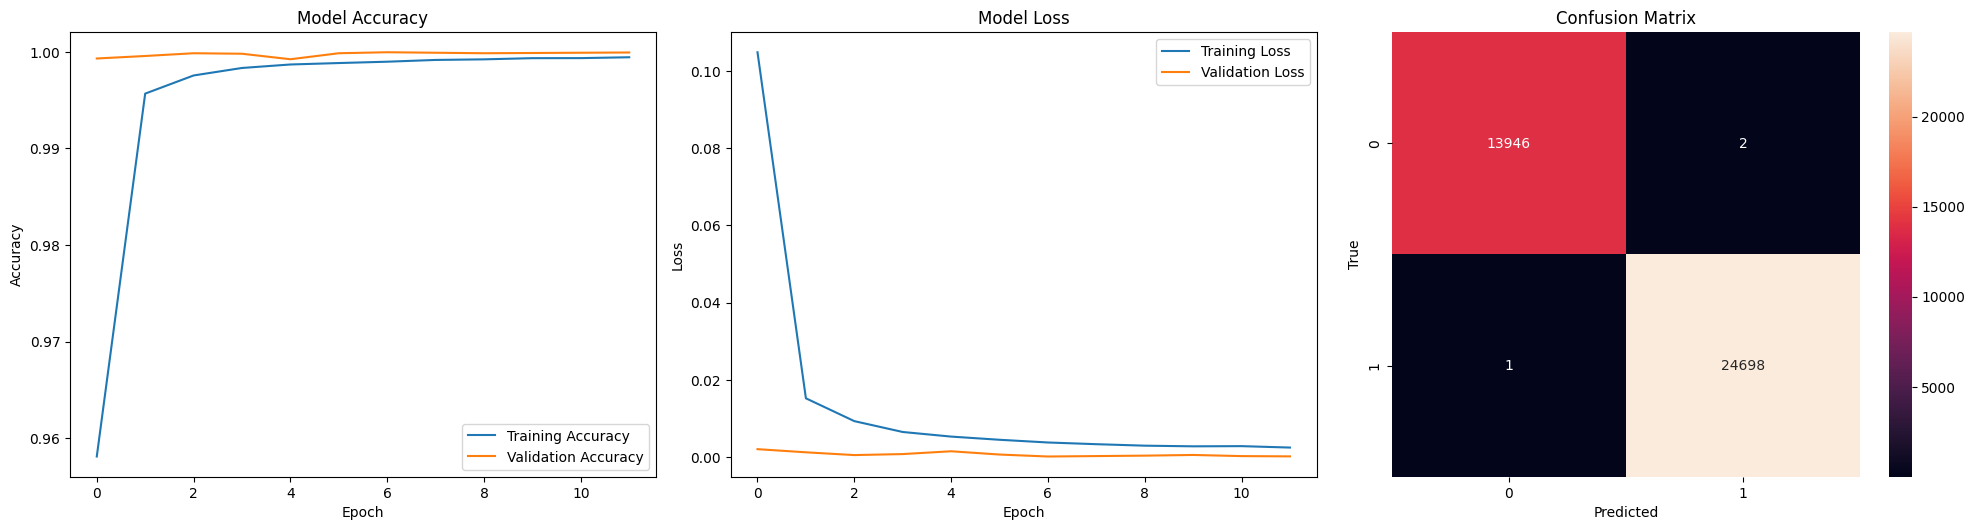

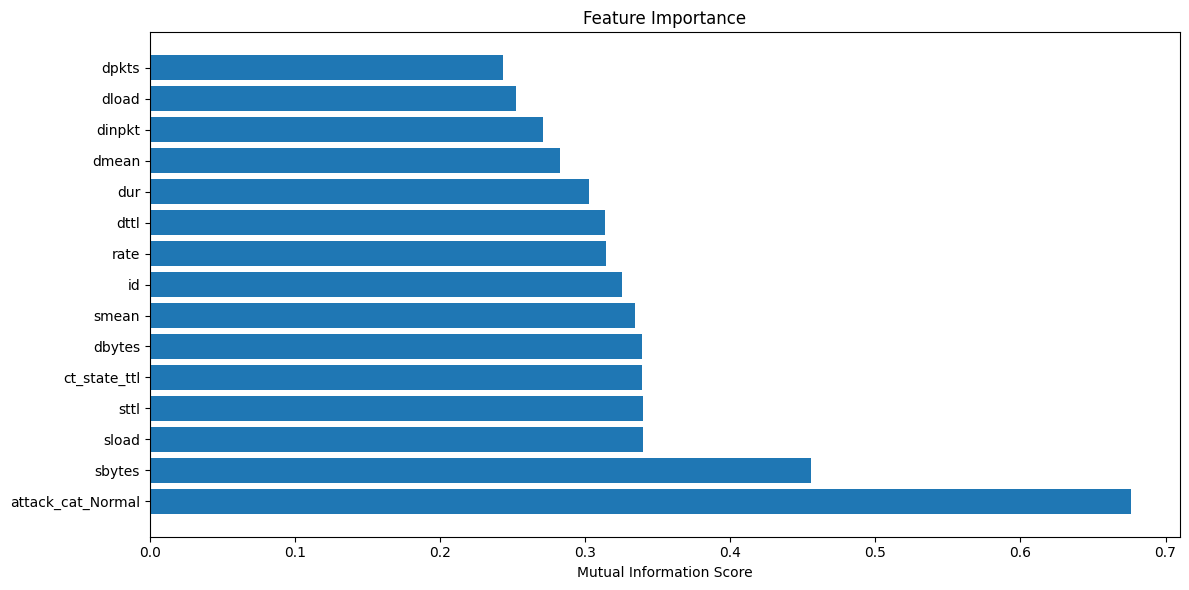

In [2]:
def load_and_prepare_data(filepath, n_features=15, train_size=0.7, val_size=0.15):
    """Load, preprocess data with advanced feature selection and split into train, val, test"""
    df = pd.read_csv(filepath)
    
    X = df.drop(['label'], axis=1) 
    y = df['label']
    
    # Store original feature names
    feature_names = X.columns.tolist()
    
    # Handle categorical features
    categorical_columns = X.select_dtypes(include=['object']).columns
    X = pd.get_dummies(X, columns=categorical_columns)
    
    # Scale features
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Feature selection using mutual information
    mi_scores = mutual_info_classif(X_scaled, y)
    mi_scores_dict = dict(zip(X.columns, mi_scores))
    selected_features = dict(sorted(mi_scores_dict.items(), key=lambda x: x[1], reverse=True)[:n_features])
    
    # Select top features
    selected_indices = [list(X.columns).index(feature) for feature in selected_features.keys()]
    X_selected = X_scaled[:, selected_indices]
    
    # Split data
    X_train, X_temp, y_train, y_temp = train_test_split(X_selected, y, 
                                                       test_size=1-train_size, 
                                                       random_state=42, 
                                                       stratify=y)
    
    test_val_size = 1 - train_size
    val_ratio = val_size / test_val_size
    
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, 
                                                   test_size=0.5, 
                                                   random_state=42, 
                                                   stratify=y_temp)
    
    # Standardize
    std_scaler = StandardScaler()
    X_train = std_scaler.fit_transform(X_train)
    X_val = std_scaler.transform(X_val)
    X_test = std_scaler.transform(X_test)
    
    # Create temporal windows
    window_size = 5
    X_train = create_temporal_windows(X_train, window_size)
    X_val = create_temporal_windows(X_val, window_size)
    X_test = create_temporal_windows(X_test, window_size)
    
    y_train = y_train[window_size-1:]
    y_val = y_val[window_size-1:]
    y_test = y_test[window_size-1:]
    
    return (X_train, X_val, X_test, y_train, y_val, y_test, 
            selected_features, mi_scores_dict)

def create_temporal_windows(X, window_size):
    """Create temporal windows with sliding window approach"""
    windows = []
    for i in range(len(X) - window_size + 1):
        windows.append(X[i:i+window_size])
    return np.array(windows)

def build_improved_model(input_shape):
    """Construct simplified CNN-BiLSTM model with attention"""
    inputs = Input(shape=input_shape)
    
    # First CNN block with reduced complexity
    x = Conv1D(filters=64, kernel_size=3, activation='relu', padding='same')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.4)(x)
    
    # Second CNN block
    x = Conv1D(filters=128, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(pool_size=2)(x)
    x = Dropout(0.4)(x)
    
    # Attention mechanism
    attention_output = MultiHeadAttention(num_heads=2, key_dim=64)(x, x)
    x = tf.keras.layers.Add()([x, attention_output])
    x = BatchNormalization()(x)
    
    # BiLSTM with reduced units
    lstm_out = Bidirectional(LSTM(units=64, return_sequences=True))(x)
    lstm_out = Dropout(0.4)(lstm_out)
    
    x = Flatten()(lstm_out)
    x = Dense(64, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    
    outputs = Dense(1, activation='sigmoid')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    return model

def plot_metrics_detailed(history, y_test, test_preds):
    """Create detailed visualizations of model performance"""
    # Create a figure with subplots
    fig = plt.figure(figsize=(20, 10))
    
    # 1. Training History
    ax1 = plt.subplot(231)
    ax1.plot(history.history['accuracy'], label='Training Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title('Model Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    
    # 2. Loss History
    ax2 = plt.subplot(232)
    ax2.plot(history.history['loss'], label='Training Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title('Model Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    
    # 3. Confusion Matrix
    ax3 = plt.subplot(233)
    cm = confusion_matrix(y_test, test_preds)
    sns.heatmap(cm, annot=True, fmt='d', ax=ax3)
    ax3.set_title('Confusion Matrix')
    ax3.set_xlabel('Predicted')
    ax3.set_ylabel('True')
    
    plt.tight_layout()
    plt.show()

def plot_feature_importance(selected_features):
    """Visualize feature importance scores"""
    plt.figure(figsize=(12, 6))
    features = list(selected_features.keys())
    scores = list(selected_features.values())
    
    plt.barh(range(len(features)), scores)
    plt.yticks(range(len(features)), features)
    plt.xlabel('Mutual Information Score')
    plt.title('Feature Importance')
    plt.tight_layout()
    plt.show()

def train_and_evaluate(filepath, epochs=50):
    """Train and evaluate the improved model"""
    # Load and prepare data
    (X_train, X_val, X_test, y_train, y_val, y_test, 
     selected_features, mi_scores) = load_and_prepare_data(filepath)
    
    # Build and compile model
    model = build_improved_model(input_shape=(X_train.shape[1], X_train.shape[2]))
    model.compile(optimizer=Adam(learning_rate=0.001), 
                 loss='binary_crossentropy', 
                 metrics=['accuracy'])
    
    # Early stopping
    early_stop = EarlyStopping(monitor='val_loss', 
                              patience=5, 
                              restore_best_weights=True)
    
    # Train model
    history = model.fit(X_train, y_train, 
                       validation_data=(X_val, y_val),
                       epochs=epochs, 
                       batch_size=32,
                       callbacks=[early_stop],
                       verbose=1)
    
    # Generate predictions
    test_preds = (model.predict(X_test) > 0.5).astype(int)
    
    # Print performance metrics
    print("\nModel Performance:")
    print("Test Accuracy:", accuracy_score(y_test, test_preds))
    print("Test ROC AUC:", roc_auc_score(y_test, test_preds))
    print("\nClassification Report:")
    print(classification_report(y_test, test_preds))
    
    # Print selected features and their importance scores
    print("\nSelected Features and Their Importance Scores:")
    for feature, score in selected_features.items():
        print(f"{feature}: {score:.4f}")
    
    # Visualize results
    plot_metrics_detailed(history, y_test, test_preds)
    plot_feature_importance(selected_features)
    
    return model, history

if __name__ == "__main__":
    dataset_path = '/kaggle/input/dataset/UNSW_NB15_merged.csv'
    model, history = train_and_evaluate(dataset_path)